# Step 6 (Week 4): can machine learning beat the near-infrared rule?

**Data:** my 255 labeled spots (59 water), 21 clues per spot (`src/features.py`): 6 color bands before and after, water indexes, near-infrared and SWIR change, and radar.

**Models:**
- **Logistic regression:** one straight dividing line through the clues.
- **Random forest:** 300 small decision trees that vote.
- **Baseline:** the dark-in-NIR rule (no training; its cutoff was picked from a histogram, not from my labels).

**Fair testing, practice exams by area:** the box is cut into 16 blocks. Each exam hides whole blocks, trains on the rest, and grades the hidden blocks. Neighbouring spots look almost the same, so hiding single spots would let the model peek through a neighbour (the Project 0 lesson: split by engine, not by row).

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220)
step6 = importlib.import_module('06_machine_learning')
step6.main()

/Users/co2/Downloads/nc-hls-mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


255 labeled spots, 59 water; 21 clues; 14 of 16 blocks contain spots
  area exam 1: 53 spots, 11 water, blocks [np.int64(0), np.int64(9)]
  area exam 2: 50 spots, 16 water, blocks [np.int64(10), np.int64(11)]
  area exam 3: 52 spots, 14 water, blocks [np.int64(1), np.int64(4), np.int64(5), np.int64(13)]
  area exam 4: 51 spots, 8 water, blocks [np.int64(3), np.int64(6), np.int64(7), np.int64(8)]
  area exam 5: 49 spots, 10 water, blocks [np.int64(14), np.int64(15)]



Practice exams by AREA (fair):
                map  caught (recall)  right when it says flood (precision)  overall accuracy  flood km2 by map  estimated real flood km2 recall 95% range precision 95% range    F1
        dark-in-NIR            0.438                                 0.478             0.959            11.278                    12.309          26%-82%             38%-59% 0.457
logistic regression            0.254                                 0.501             0.960             6.252                    12.309          14%-52%             36%-64% 0.337
      random forest            0.234                                 0.590             0.963             4.877                    12.309          12%-48%             43%-74% 0.335



Ordinary RANDOM practice exams (can look too good):
                map  caught (recall)  right when it says flood (precision)  overall accuracy  flood km2 by map  estimated real flood km2 recall 95% range precision 95% range    F1
        dark-in-NIR            0.438                                 0.478             0.959            11.278                    12.309          26%-82%             38%-59% 0.457
logistic regression            0.255                                 0.610             0.964             5.134                    12.309          14%-52%             46%-76% 0.359
      random forest            0.244                                 0.600             0.964             5.002                    12.309          13%-49%             45%-75% 0.347

Random forest: most-used clues
nir_after      0.094
green_after    0.085
nir_ratio      0.079
nir_before     0.069
ndwi_before    0.068
swir1_after    0.064
swir1_ratio    0.057
swir2_after    0.048



Random-forest flood map: 6.2 km2 (rule: 11.3 km2)
Saved figures/06_*.png, results/06_*.csv, data/06_flood_random_forest.tif


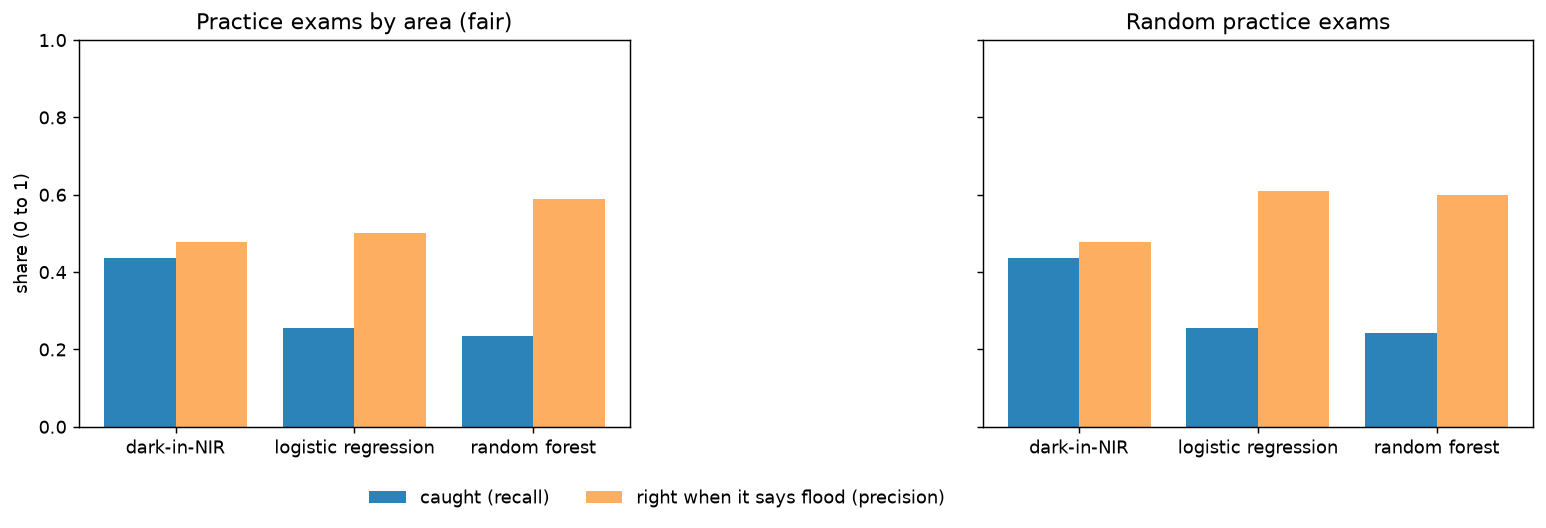

In [2]:
display(Image(filename='../figures/06_ml_vs_rule.png'))

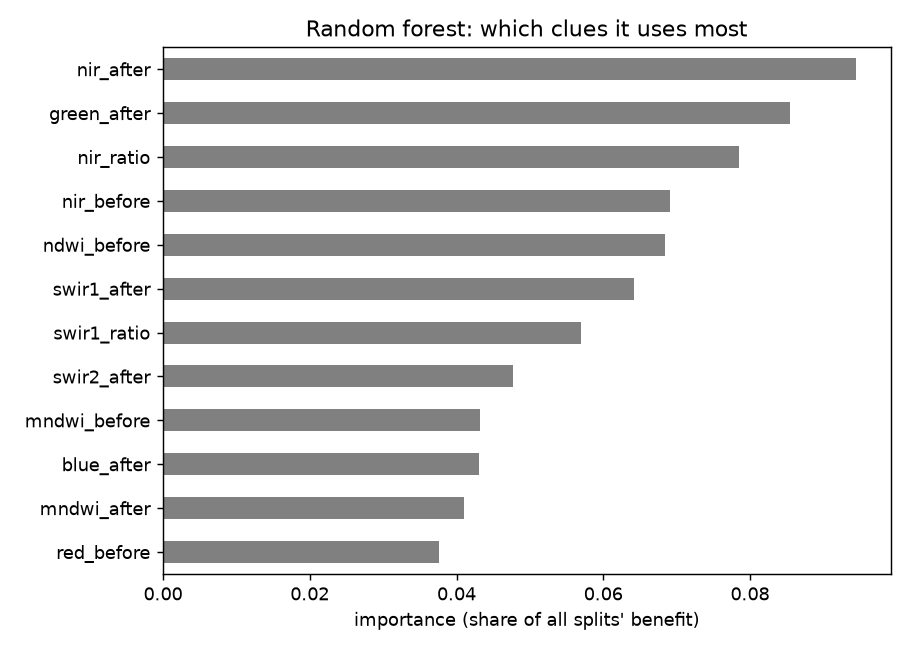

In [3]:
display(Image(filename='../figures/06_clue_importance.png'))

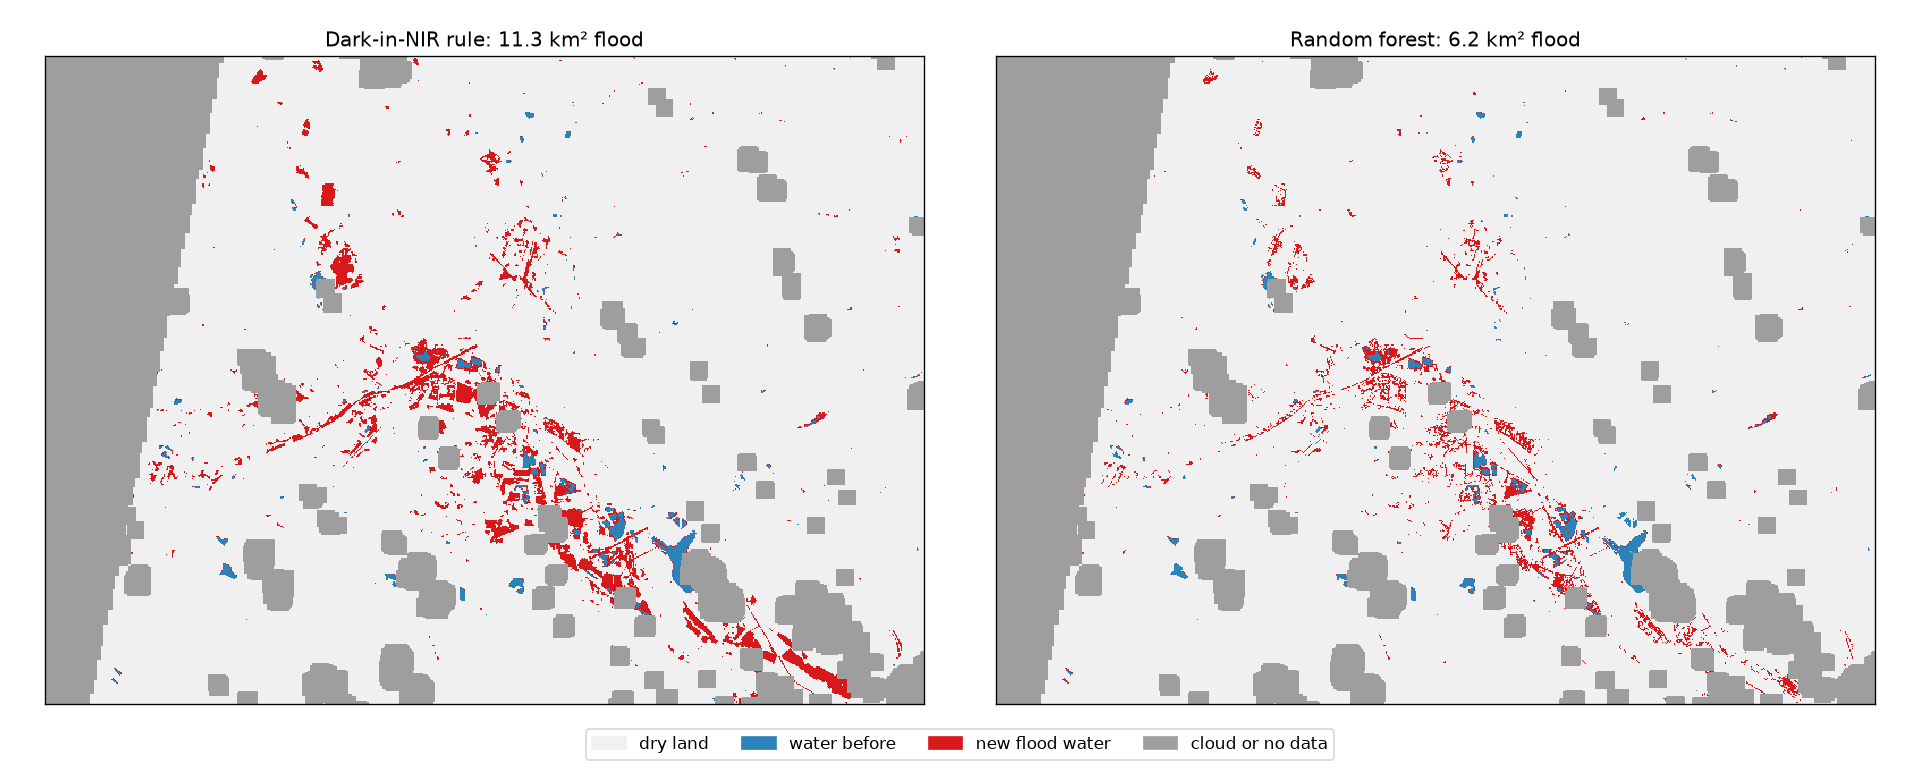

In [4]:
display(Image(filename='../figures/06_rf_flood_map.png'))

## What we learned
- **Machine learning did not beat the rule.** Fair (by-area) grades: the rule catches 44% of the flood; logistic regression 25%, random forest 23%. The models are pickier: when the random forest says flood it is right 59% of the time vs 48% for the rule, but it misses far more. Balanced score (F1): rule 0.46, models 0.34.
- **Random practice exams look better than they should.** Logistic regression's precision is 61% with random exams but 50% by area: neighbouring spots leak answers. The by-area grade is the honest one.
- **The forest leans on near-infrared** (after, before, and the change), plus green and SWIR, the same clues the rule uses. Radar clues are barely used.
- **Likely reasons (not proven):** only 255 labels (59 water); the clues can't see water under trees either; and the model learned to be cautious because most labeled spots are dry.
- **Ideas for later:** more labels, choosing the model's yes/no cutoff with an extra inner practice exam, or clues from neighbouring pixels.